In [2]:
import pandas as pd
import numpy as np
from scipy.optimize import root, brentq
from sklearn.metrics import mean_squared_error
from scipy.special import ndtr
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('../Data/aggregation/BA_for_CG.csv')
df["Date"] = pd.to_datetime(df["Date"])
df = df[df["Date"].between("2018-01-01", "2025-01-01", inclusive="neither")]
df = df.dropna(subset=["Close", "IV", "Z", "rf", "STD", "LTD", "Shares"])
maturity = pd.Timestamp("2038-02-15")
df["T"] = (maturity - df["Date"]).dt.days / 365.25
df["B"] = (df["STD"] + df["LTD"]) / df["Shares"]

In [4]:
def calibrate_iv(S, vol, B, T, r):
    pv = B * np.exp(-r * T)

    def equations(z):
        V, sigma_V = np.exp(z)
        d1 = (np.log(V / B) + (r + sigma_V**2 / 2) * T) / (sigma_V * np.sqrt(T))
        d2 = d1 - sigma_V * np.sqrt(T)
        return [(V * ndtr(d1) - pv * ndtr(d2)) / S - 1,
                sigma_V * V * ndtr(d1) / (vol * S) - 1]

    V0 = S + pv
    V, sigma_V = np.exp(root(equations, np.log([V0, vol * S / V0])).x)
    d1 = (np.log(V / B) + (r + sigma_V**2 / 2) * T) / (sigma_V * np.sqrt(T))
    d2 = d1 - sigma_V * np.sqrt(T)
    debt = V * ndtr(-d1) + pv * ndtr(d2)
    return V, sigma_V, -np.log(debt / pv) / T * 10000

In [5]:
def calibrate_z(S, Z, B, T, r):
    pv = B * np.exp(-r * T)
    V = S + B * np.exp(-(r + Z / 10000) * T)

    def equation(sigma_V):
        d1 = (np.log(V / B) + (r + sigma_V**2 / 2) * T) / (sigma_V * np.sqrt(T))
        d2 = d1 - sigma_V * np.sqrt(T)
        return V * ndtr(d1) - pv * ndtr(d2) - S

    sigma_V = brentq(equation, 1e-6, 5)
    d1 = (np.log(V / B) + (r + sigma_V**2 / 2) * T) / (sigma_V * np.sqrt(T))
    return V, sigma_V, sigma_V * V * ndtr(d1) / S

In [6]:
result = df[["Date", "Z", "IV"]].rename(columns={"Z": "Z_spread"})
result[["V_IV", "sigma_V_IV", "Z_from_IV"]] = df.apply(
    lambda row: calibrate_iv(row["Close"], row["IV"], row["B"], row["T"], row["rf"] / 100),
    axis=1, result_type="expand"
)
result[["V_Z", "sigma_V_Z", "IV_from_Z"]] = df.apply(
    lambda row: calibrate_z(row["Close"], row["Z"], row["B"], row["T"], row["rf"] / 100),
    axis=1, result_type="expand"
)
result

,Date,Z_spread,IV,V_IV,sigma_V_IV,Z_from_IV,V_Z,sigma_V_Z,IV_from_Z
503,2018-01-02,109.249072,0.23815,307.326389,0.230041,0.348368,305.262989,0.482986,0.494625
504,2018-01-03,107.415780,0.23405,308.332094,0.226069,0.276773,306.289988,0.481082,0.492749
505,2018-01-04,109.310532,0.23390,307.198215,0.225898,0.276724,305.124829,0.482759,0.494442
506,2018-01-05,99.885654,0.23575,319.330771,0.228018,0.273329,317.426172,0.476294,0.487646
507,2018-01-08,106.192629,0.23915,320.627307,0.231351,0.325940,318.618698,0.483281,0.494532
...,...,...,...,...,...,...,...,...,...
2259,2024-12-24,153.571425,0.37495,225.115337,0.307446,69.431405,220.322628,0.382900,0.451970
2260,2024-12-26,154.236880,0.37085,226.428842,0.303790,65.721219,221.373043,0.383932,0.452793
2261,2024-12-27,155.135377,0.36860,226.589344,0.302075,63.474610,221.385884,0.385543,0.454001
2262,2024-12-30,146.711071,0.36270,223.033363,0.295058,60.027431,218.033520,0.375776,0.445801


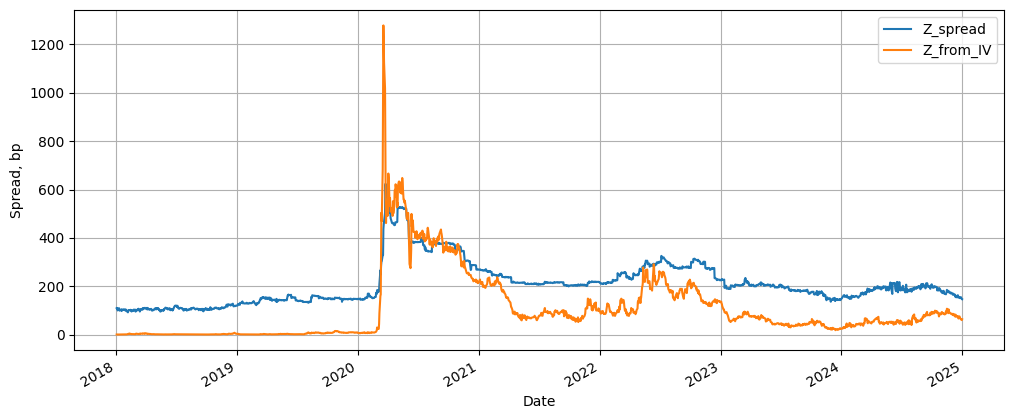

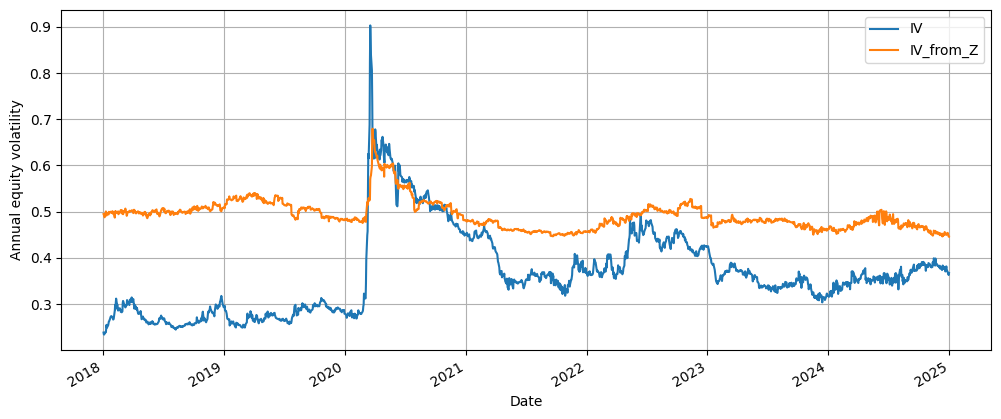

In [7]:
ax = result.plot(x="Date", y=["Z_spread", "Z_from_IV"], figsize=(12, 5), grid=True)
ax.set_ylabel("Spread, bp")
plt.show()

ax = result.plot(x="Date", y=["IV", "IV_from_Z"], figsize=(12, 5), grid=True)
ax.set_ylabel("Annual equity volatility")
plt.show()

In [9]:
mse = mean_squared_error(result['IV'], result["IV_from_Z"])
ll = -len(result) / 2 * (np.log(2 * np.pi * mse) + 1)
print(mse)
print(ll)

0.02302976823233718
821.5862402981032
